# import pandas, matplotlib and seaborn

In [13]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [14]:
import warnings
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

#import sklearn for kmeans, iLinear regression, Random Forest, Decision Tree. Also import train test split, mean absolute  error, mean squared error and r2 score.

In [15]:
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor



In [16]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



#Load in csv retail_sales_data as df.  show dtypes.

In [17]:
df = pd.read_csv(r"C:\Users\mcnicholst\Downloads\codespaces-jupyter\Python & csv\retail_sales_data.csv")
display(df.dtypes)

Customer_Join_Date        str
Transaction_Date          str
Region                    str
Store_ID                  str
Product_Segment           str
Unit_Price            float64
Quantity_Sold           int64
Marketing_Spend       float64
dtype: object

#Always convert columns with str that should be date/time.  
change the customer join and transaction date to pd.to_datetime.

In [18]:
df["Customer_Join_Date"] = pd.to_datetime(df["Customer_Join_Date"])
df["Transaction_Date"] = pd.to_datetime(df["Transaction_Date"])
df.head(3)

,Customer_Join_Date,Transaction_Date,Region,Store_ID,Product_Segment,Unit_Price,Quantity_Sold,Marketing_Spend
0,2023-12-13,2025-11-13,North,Store_103,Beauty,377.80,8,1410.40
1,2022-12-18,2024-12-26,North,Store_108,Beauty,405.35,6,1603.12
2,2024-09-03,2025-11-22,South,Store_108,Clothing,495.35,8,945.73


In [24]:
#Feature engineering related to date columns
df["Customer_Loyalty Days"] = (df["Transaction_Date"] - df["Customer_Join_Date"]).dt.days

#create revenue column
df["Revenue"] = df["Quantity_Sold"] * df["Unit_Price"]  

#Feature engineering related revenue columns
df["Revenue_Per_Customer"] = df["Revenue"] / (df["Customer_Age"] + 1)

#feature engineering related to day of the week
df["Transaction_Day_Of_Week"] = df["Transaction_Date"].dt.dayofweek

#feature engineering related to month of the year
df["Transaction_Month"] = df["Transaction_Date"].dt.month_name()

#feature engineering related to weekend vs weekday  (5-6 = weekend, 0-4 = weekday)
df["Is_Weekend"] = df["Transaction_Day_Of_Week"] >= 5

df.head(3)

,Customer_Join_Date,Transaction_Date,Region,Store_ID,Product_Segment,Unit_Price,Quantity_Sold,Marketing_Spend,Customer_Age,Revenue,Revenue_Per_Customer,Transaction_Day_Of_Week,Transaction_Month,Transaction_Weekend,Customer_Loyalty Days,Is_Weekend
0,2023-12-13,2025-11-13,North,Store_103,Beauty,377.80,8,1410.40,1,3022.4,1511.2,3,November,False,701,False
1,2022-12-18,2024-12-26,North,Store_108,Beauty,405.35,6,1603.12,2,2432.1,810.7,3,December,False,739,False
2,2024-09-03,2025-11-22,South,Store_108,Clothing,495.35,8,945.73,1,3962.8,1981.4,5,November,True,445,True


#K-Means Customer Clustering.  
cluster using K means based on columns - Revenue, Customer Loyalty, Marketing Spend.  Create Customer_Clusters based on groupby cluster cols.

In [25]:
from sklearn.preprocessing import StandardScaler

cluster_cols = ["Revenue", "Customer_Loyalty Days", "Marketing_Spend"]

# Scale features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[cluster_cols])

# Fit K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(scaled_features)

# Summarize clusters
Customer_Clusters = df.groupby("Cluster")[cluster_cols].mean()
Customer_Clusters["Customer_Count"] = df.groupby("Cluster").size()

display(Customer_Clusters)

,Revenue,Customer_Loyalty Days,Marketing_Spend,Customer_Count
Cluster,,,,
0,619.357857,792.928571,1299.951071,28
1,758.120698,282.000000,915.986047,43
2,2508.649310,599.172414,723.861724,29


#Generate a visualisation odf the clusters by segments, revenue and marketing spend.

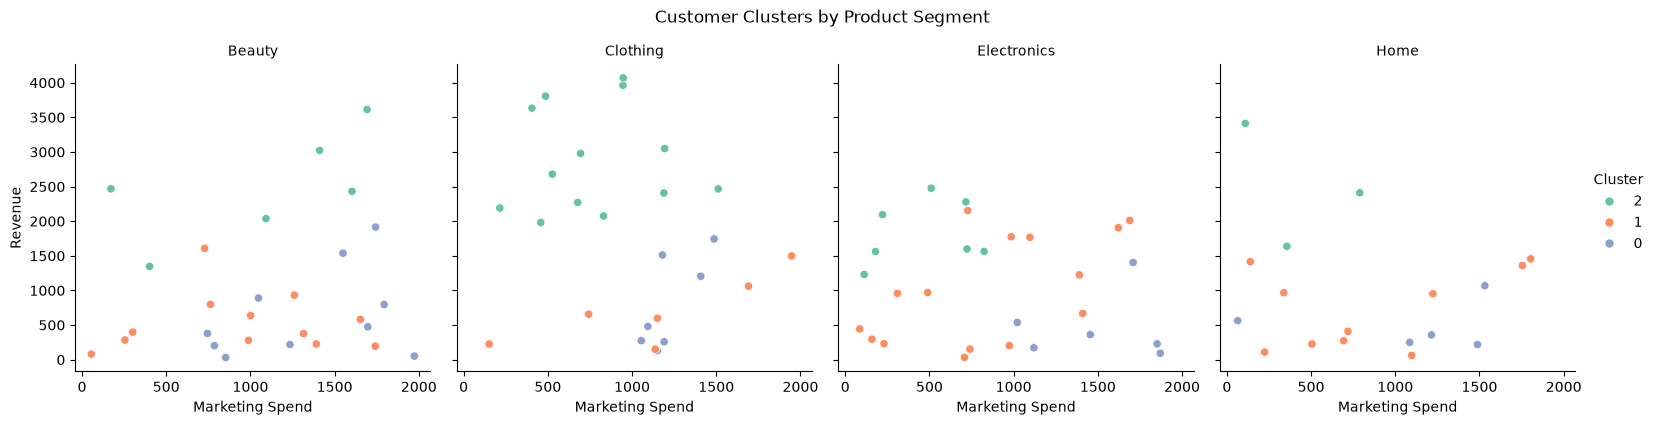

In [26]:
cluster_plot = sns.relplot(
    data=df.assign(Cluster=df["Cluster"].astype(str)),
    x="Marketing_Spend",
    y="Revenue",
    hue="Cluster",
    col="Product_Segment",
    kind="scatter",
    palette="Set2",
    height=4,
    aspect=1
)

cluster_plot.set_axis_labels("Marketing Spend", "Revenue")
cluster_plot.set_titles("{col_name}")
cluster_plot.fig.suptitle("Customer Clusters by Product Segment", y=1.05)
plt.show()

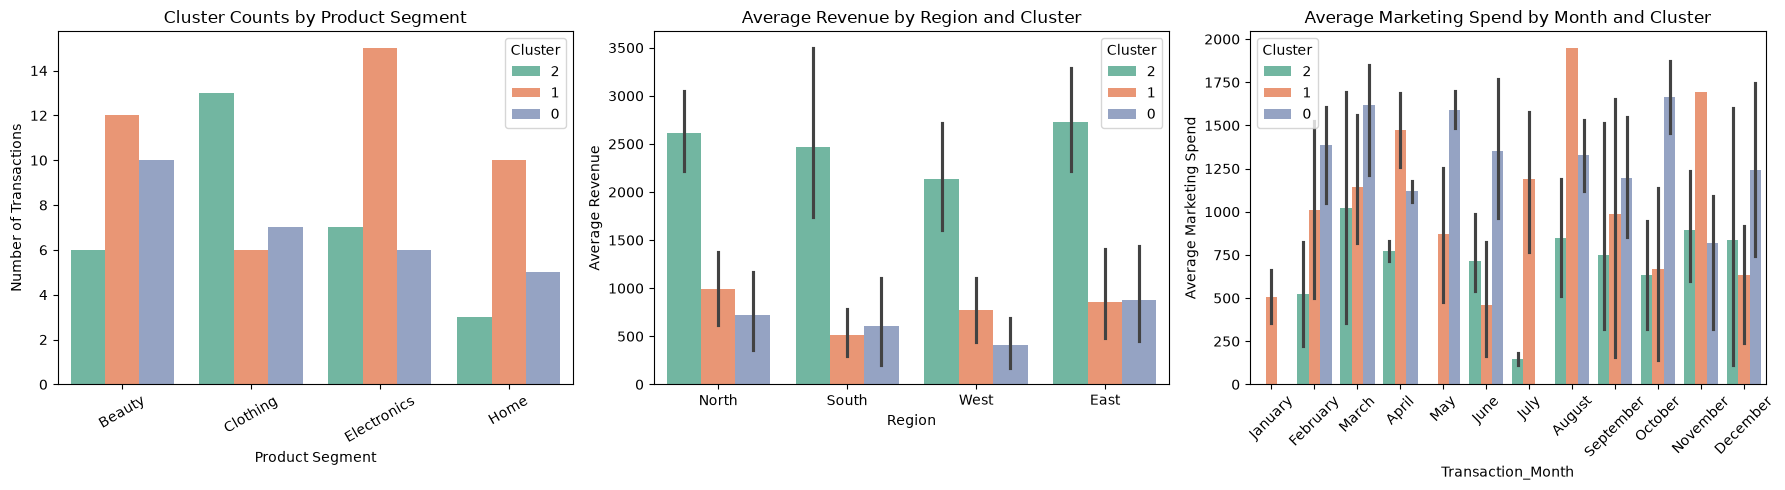

In [27]:
plot_df = df.copy()
plot_df["Cluster"] = plot_df["Cluster"].astype(str)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Cluster counts across product segments
sns.countplot(data=plot_df, x="Product_Segment", hue="Cluster", ax=axes[0], palette="Set2")
axes[0].set_title("Cluster Counts by Product Segment")
axes[0].set_xlabel("Product Segment")
axes[0].set_ylabel("Number of Transactions")
axes[0].tick_params(axis="x", rotation=30)

# Average revenue across regions
sns.barplot(data=plot_df, x="Region", y="Revenue", hue="Cluster", ax=axes[1], palette="Set2")
axes[1].set_title("Average Revenue by Region and Cluster")
axes[1].set_ylabel("Average Revenue")

# Average marketing spend by transaction month
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]
sns.barplot(
    data=plot_df, x="Transaction_Month", y="Marketing_Spend",
    hue="Cluster", order=month_order, ax=axes[2], palette="Set2"
)
axes[2].set_title("Average Marketing Spend by Month and Cluster")
axes[2].set_ylabel("Average Marketing Spend")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

##Generate a visualisation odf the clusters by segments, revenue and marketing spend.#Generate a visualisation odf the clusters by segments, revenue and marketing spend.

In [ ]:
segment_cluster_plot = sns.relplot(
    data=df,
    x="Marketing_Spend",
    y="Revenue",
    hue="Cluster",
    col="Product_Segment",
    kind="scatter",
    palette="Set2",
    height=4,
    aspect=1
)

segment_cluster_plot.set_axis_labels("Marketing Spend", "Revenue")
segment_cluster_plot.set_titles("{col_name}")
segment_cluster_plot.fig.suptitle(
    "Customer Clusters by Product Segment",
    y=1.05
)
plt.show()

create a Decision tree with regression branch splitting map.  use model decision tree

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 9))
plot_tree(
    revenue_tree,
    feature_names=features,
    filled=True,
    rounded=True,
    precision=2,
)
plt.title("Decision Tree Regression: Revenue Splits")
plt.show()

In [28]:
# Predict Revenue using numeric transaction and customer features
features = [
    "Unit_Price",
    "Quantity_Sold",
    "Marketing_Spend",
    "Customer_Age",
    "Customer_Loyalty Days",
]
X = df[features]
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

revenue_tree = DecisionTreeRegressor(max_depth=3, random_state=42)
revenue_tree.fit(X_train, y_train)

plt.figure(figsize=(18, 9))
plot_tree(
    revenue_tree,
    feature_names=features,
    filled=True,
    rounded=True,
    precision=2,
)
plt.title("Decision Tree Regression: Revenue Splits")
plt.show()

NameError: name 'plot_tree' is not defined

<Figure size 1800x900 with 0 Axes>